# Figure S5 — Sensitivity of GLORYS12 to changes in the in-situ observing network

Addresses reviewer comments on (i) whether the nonlinear (pre/post-2015) changes
diagnosed from GLORYS12 could be artefacts of changes in the observing network,
particularly in the marginal ice zone (MIZ), and (ii) the sensitivity of the
conclusions to GLORYS12 fidelity (e.g. Fig. S4 FWT agreement).

The figure tests three predictions of the "network artefact" hypothesis:

1. **Where did the network grow?** (panels a–c) Argo profile density per period,
   and annual counts split by GLORYS12 sea-ice class (open water / MIZ / ice-covered).
2. **Does the GLORYS12−Argo mismatch drift as the network grows?** (panel d)
   Annual-mean 10–200 m bias with Period 1 / Period 2 trends. NB: Argo profiles are
   assimilated by GLORYS12, so this is a consistency check, not independent validation.
3. **Does GLORYS12 reproduce observed trends at fixed sites?** (Figure S6 a–d) Trend in
   GLORYS12 vs trend in observations, per period, at the Fram Strait moorings
   (fixed locations, ice-covered/MIZ EGC) and for FSAOO freshwater transport and
   D34.5 isohaline depth.

Reuses cached comparison data from figure_s02 (Argo paired file), figure_s03
(moorings) and figure_s04 (FWT, D34.5). Only the Argo profile table, the GLORYS12
sea-ice lookup and the March ice-edge fields are (re)built here, gated by REPROCESS.

**Outputs**
- Figure: `./outputs/figures/figure_s05_observing_network_sensitivity.png`
- Figure: `./outputs/figures/figure_s06_trend_fidelity.png` (trend-fidelity scatters)
- Additional diagnostic figure: `./outputs/figures/figure_s05_ref_mooring_bias_timeseries.png`
- Processed data: `./outputs/processed_data/figure_s05/`
- Methods: `./outputs/methods/figure_s05_methodology.md`
- Log: `./outputs/logs/figure_s05.log`

Version 0.2.6 — Author: Chris Barrell

In [1]:
import os
import sys
import glob
import logging
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import scipy.io as sio
from scipy import stats
import pymannkendall as mk

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch, FancyBboxPatch
from matplotlib.path import Path as MplPath
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patheffects as pe
# Truncated yellow-green so the navy ice-edge contour and orange casts stand out
CMAP_COUNTS = LinearSegmentedColormap.from_list(
    'ylgn_trunc', plt.get_cmap('YlGn')(np.linspace(0.10, 0.85, 256)))

warnings.filterwarnings("ignore")

sys.path.append('..')
try:
    from utils.logger import get_logger
    logger = get_logger(__name__, config_path='../config.yaml')
except Exception:
    logger = logging.getLogger(__name__)
    logging.basicConfig(level=logging.INFO)

# ============================================================================
# CONFIGURATION
# ============================================================================

VERSION   = '0.2.6'
REPROCESS = True   # True: rebuild Argo table, GLORYS12 SIC lookup, ice edges, cast positions

# --- Inputs ---
GLORYS_PATH      = '../../glorys12_with_density/glorys12_*_Greenland_Sea_with_density.nc'
ARGO_PAIRED_FILE = './outputs/processed_data/argo/argo_glorys_paired_profiles_v2.nc'  # from argo_glorys_pairing.ipynb
ARGO_TIME_VAR_CANDIDATES = ['time', 'juld', 'JULD', 'date']

S03_MOORING_CSV = './outputs/processed_data/figure_s03/glorys_mooring_collocated.csv'
S04_FWT_CSV     = './outputs/processed_data/figure_s04_FS_FWT/glorys_obs_fwt_comparison.csv'
S04_D345_CSV    = './outputs/processed_data/figure_s04_FS_FWT/d345_isohaline_depth_comparison.csv'

IGP_CTD_FILE  = '/local/jbj13rpu/Documents/ROVER/IGP_data/IGP_CTD.nc'
IGP_XCTD_FILE = '/local/jbj13rpu/Documents/ROVER/IGP_data/IGP_XCTD.nc'
KH_MAT_FILE   = '/local/jbj13rpu/Documents/ROVER/KH_CTD/kh2025007002.mat'

# --- Locked project conventions ---
SPLIT_YEAR    = 2015            # Period 1: year < 2015 ; Period 2: year >= 2015
DATA_END_DATE = '2026-04-30'
N_BOOTSTRAP   = 1000
SEED          = 42

GREENLAND_SEA_COORDS = [(-22, 71), (-8.5, 71), (12, 79), (-21, 79), (-28, 73), (-22, 71)]

MOORING_POSITIONS = {            # (lat, lon), from figure_s03
    "F17": (78.838, -8.107),
    "F14": (78.814, -6.503),
    "F13": (78.836, -5.000),
    "F12": (78.816, -3.990),
    "F11": (78.808, -3.053),
}
MOORING_ORDER = ["F17", "F14", "F13", "F12", "F11"]   # west to east

# --- Argo depth band (DEPTH_MIN matches figure_s02) ---
ARGO_DEPTH_MIN  = 10.0    # m
ARGO_DEPTH_MAX  = 200.0   # m
ARGO_MIN_LEVELS = 5       # min jointly-valid levels in band for a profile to count

# --- Sea-ice classes from GLORYS12 siconc at profile location/month ---
MIZ_SIC_MIN = 0.15
MIZ_SIC_MAX = 0.80
# GLORYS12 siconc is NaN (not 0) over ice-free ocean. 'zero': set NaN siconc to 0
# wherever surface thetao is finite (ocean), so only land/outside-grid stays 'unknown'.
# 'keep': leave NaN as-is (v0.2.0 behaviour).
SIC_NAN_OVER_OCEAN = 'zero'
ICE_CLASSES = ['open_water', 'miz', 'ice_covered', 'unknown']
ICE_CLASS_LABELS = {
    'open_water':  'Open water (SIC < 15%)',
    'miz':         'MIZ (15–80%)',
    'ice_covered': 'Ice-covered (SIC > 80%)',
    'unknown':     'SIC unavailable',
}

# --- Panel (d) annual bias ---
BIAS_REGION = 'all'       # 'all' (GS polygon) | 'fixed_box'
# Sub-region used only when BIAS_REGION = 'fixed_box'
FIXED_BOX = dict(lon_min=-10.0, lon_max=5.0, lat_min=73.5, lat_max=77.5)
ANNUAL_MIN_PROFILES = 1   # keep all years; precision handled by weighting below
ANNUAL_WEIGHTING    = 'n' # 'n': weighted least squares, weight = profiles per year
                          #      (inverse variance, since SE of a mean ~ 1/sqrt(n)); 'none': OLS
SENS_MIN_PROFILES   = 20  # threshold used only in the methods sensitivity table
MIN_ANNUAL_POINTS   = 5   # min years per period for an annual trend
# --- Panel (d): mooring annual bias ---
MOOR_MIN_MONTHS     = 9     # min months with data for a calendar-year mean bias
MOORING_TRENDS      = True  # single full-record trend per mooring (thin dashed, no shading)
ANNUAL_TREND_MODE   = 'full'  # panel (d): 'full' = single linear trend over the whole record
                              # (tests stationarity of the GLORYS12-Argo mismatch; the physical
                              # breakpoint is not imposed on a data diagnostic); 'split' = P1/P2

# --- Figure S6 (a–d) trend fidelity ---
MIN_SPAN_YEARS = 5.0      # min time span of matched months within a period
MIN_MONTHS     = 36       # min matched months within a period
BLOCK_LEN      = 12       # moving-block bootstrap block length (months)

# --- Maps ---
MAP_EXTENT      = [-30, 16, 67, 81.5]   # lon_min, lon_max, lat_min, lat_max
GRID_DLON       = 1.0
GRID_DLAT       = 0.5
ICE_EDGE_MONTH  = 3       # winter maximum (March)
ICE_EDGE_MONTH_MIN = 9    # summer minimum (September)
ICE_EDGE_SIC    = 0.15
DRAW_COASTLINES = True
POLY_DENSIFY_N  = 100     # points per polygon edge, so edges follow lat/lon lines on the map

# --- Outputs ---
OUTPUT_DIR         = './outputs/figures/'
PROCESSED_DIR      = './outputs/processed_data/figure_s05/'
OUTPUT_METHODS_DIR = './outputs/methods/'
LOG_DIR            = './outputs/logs/'
for d in [OUTPUT_DIR, PROCESSED_DIR, OUTPUT_METHODS_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

OUT_FIG     = OUTPUT_DIR + 'figure_s05_observing_network_sensitivity.png'
OUT_FIG_2   = OUTPUT_DIR + 'figure_s06_trend_fidelity.png'
OUT_FIG_REF = OUTPUT_DIR + 'figure_s05_ref_mooring_bias_timeseries.png'

CSV_ARGO      = PROCESSED_DIR + 'argo_profile_table.csv'
CSV_CASTS     = PROCESSED_DIR + 'cast_positions.csv'
NC_ICE_EDGE   = PROCESSED_DIR + 'march_september_mean_sic_by_period.nc'
CSV_COVERAGE  = PROCESSED_DIR + 'argo_coverage_by_year_ice_class.csv'
CSV_ANN_BIAS  = PROCESSED_DIR + 'argo_annual_bias.csv'
CSV_ANN_TREND = PROCESSED_DIR + 'argo_annual_bias_trends.csv'
CSV_FIDELITY  = PROCESSED_DIR + 'trend_fidelity_table.csv'
CSV_PLATFORM  = PROCESSED_DIR + 'platform_period_stats.csv'
CSV_ICECLASS  = PROCESSED_DIR + 'argo_stats_by_ice_class_period.csv'
MD_METHODS    = OUTPUT_METHODS_DIR + 'figure_s05_methodology.md'

log_path = os.path.join(LOG_DIR, 'figure_s05.log')
file_handler = logging.FileHandler(log_path, mode='w')
file_handler.setLevel(logging.INFO)
file_handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
logger.addHandler(file_handler)

# --- Style (project conventions) ---
COLOR_OBS      = 'black'
COLOR_GLORYS   = '#2E86AB'
COLOR_T        = COLOR_GLORYS   # GLORYS12 blue, consistent with Figure S2
COLOR_S        = COLOR_GLORYS
COLOR_ICE_EDGE = '#0B3D91'
COLOR_ICE_EDGE_SEP = '#56B4E9'   # September contour (sky blue)
ICE_CLASS_COLORS = {'open_water': '#9ecae1', 'miz': '#3182bd',
                    'ice_covered': '#08306b', 'unknown': '0.7'}
MOORING_COLORS  = {"F17": "#1f77b4", "F14": "#ff7f0e", "F13": "#2ca02c",
                   "F12": "#d62728", "F11": "#9467bd"}
MOORING_MARKERS = {"F17": "o", "F14": "s", "F13": "^", "F12": "D", "F11": "v"}
FONTSIZE = 11
STATS_FS = 9
STATS_HEADROOM = 0.35   # fraction of y-range added above data in (d)
FIG_DPI  = 600

# Annual panels: points sit on integer years and 2015 belongs to Period 2,
# so the break line is drawn between 2014 and 2015.
BREAK_X_ANNUAL = SPLIT_YEAR - 0.5

## Section 0 — Shared helpers

In [2]:
def in_gs_polygon(lon, lat, coords=GREENLAND_SEA_COORDS):
    poly = MplPath(coords)
    return poly.contains_points(np.column_stack([np.asarray(lon), np.asarray(lat)]))


def densify_polygon(coords, n=POLY_DENSIFY_N):
    """Interpolate n points per edge in lon/lat space, so that on a projected map the
    boundary follows parallels/meridians (e.g. the 79N edge curves with the 79N
    parallel). Matches in_gs_polygon(), which also treats edges as straight in lon/lat."""
    segs = [np.column_stack([np.linspace(lo0, lo1, n, endpoint=False),
                             np.linspace(la0, la1, n, endpoint=False)])
            for (lo0, la0), (lo1, la1) in zip(coords[:-1], coords[1:])]
    segs.append(np.array([coords[-1]], dtype=float))
    return np.vstack(segs)


def normalise_lon(lon):
    return ((np.asarray(lon, dtype=float) + 180.0) % 360.0) - 180.0


def period_mask(years, period):
    """Locked convention: P1 = year < SPLIT_YEAR, P2 = year >= SPLIT_YEAR."""
    years = np.asarray(years)
    if period == 'P1':
        return years < SPLIT_YEAR
    if period == 'P2':
        return years >= SPLIT_YEAR
    if period == 'ALL':
        return np.ones(years.shape, dtype=bool)
    raise ValueError(period)


def sig_stars(p):
    if p is None or not np.isfinite(p):
        return ''
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''


def calc_stats(obs, model):
    """n, r, bias (model - obs), RMSE for paired finite values."""
    o = np.asarray(obs, dtype=float)
    m = np.asarray(model, dtype=float)
    ok = np.isfinite(o) & np.isfinite(m)
    n = int(ok.sum())
    if n < 3:
        return dict(n=n, r=np.nan, bias=np.nan, rmse=np.nan)
    o, m = o[ok], m[ok]
    r = stats.pearsonr(o, m)[0] if (np.std(o) > 0 and np.std(m) > 0) else np.nan
    return dict(n=n, r=float(r), bias=float(np.mean(m - o)),
                rmse=float(np.sqrt(np.mean((m - o) ** 2))))


def nearest_index(grid, values):
    """Nearest index on a 1-D (not necessarily ascending) coordinate."""
    grid = np.asarray(grid, dtype=float)
    values = np.asarray(values, dtype=float)
    return np.abs(grid[None, :] - values[:, None]).argmin(axis=1)


def decimal_year(times):
    t = pd.DatetimeIndex(times)
    return t.year.values + (t.month.values - 0.5) / 12.0

## Section 1 — Argo profile table (joint-masked 10–200 m means, GS polygon)

In [3]:
def band_mean_joint(obs2d, mod2d, depth_sel, min_levels):
    """Mean over depth_sel using ONLY levels where obs AND model are finite.

    Fixes the v0.1.0 bug where obs and GLORYS band means were taken over
    independently-masked levels (different level sets per profile).
    """
    o = obs2d[:, depth_sel]
    m = mod2d[:, depth_sel]
    joint = np.isfinite(o) & np.isfinite(m)
    n = joint.sum(axis=1)
    with np.errstate(invalid='ignore', divide='ignore'):
        o_mean = np.where(joint, o, 0.0).sum(axis=1) / n
        m_mean = np.where(joint, m, 0.0).sum(axis=1) / n
    bad = n < min_levels
    o_mean[bad] = np.nan
    m_mean[bad] = np.nan
    return o_mean, m_mean, n


def load_argo_profile_table(path):
    ds = xr.open_dataset(path)
    logger.info(f"Argo paired file: {path}")
    logger.info(f"  dims: {dict(ds.sizes)}")
    logger.info(f"  variables: {list(ds.data_vars)}")
    for k, v in ds.attrs.items():
        logger.info(f"  attr {k}: {v}")   # check here whether pairing used daily or monthly GLORYS

    time_var = next((v for v in ARGO_TIME_VAR_CANDIDATES if v in ds.variables), None)
    if time_var is None:
        ds.close()
        raise KeyError(f"No time variable found in {path} (tried {ARGO_TIME_VAR_CANDIDATES})")
    times = pd.to_datetime(ds[time_var].values)

    depths = np.abs(ds['depth'].values.astype(float))
    n_prof = ds.sizes['profile']
    arrs = {}
    for v in ['T_argo', 'T_glorys', 'S_argo', 'S_glorys']:
        a = ds[v].values.astype(float)
        if a.shape[0] != n_prof and a.shape[1] == n_prof:
            a = a.T
        arrs[v] = a
    lat = ds['lat'].values.astype(float)
    lon = normalise_lon(ds['lon'].values)
    ds.close()

    depth_sel = (depths >= ARGO_DEPTH_MIN) & (depths <= ARGO_DEPTH_MAX)
    T_o, T_g, nT = band_mean_joint(arrs['T_argo'], arrs['T_glorys'], depth_sel, ARGO_MIN_LEVELS)
    S_o, S_g, nS = band_mean_joint(arrs['S_argo'], arrs['S_glorys'], depth_sel, ARGO_MIN_LEVELS)

    df = pd.DataFrame({'time': times, 'lat': lat, 'lon': lon,
                       'T_obs': T_o, 'T_glorys': T_g, 'n_levels_T': nT,
                       'S_obs': S_o, 'S_glorys': S_g, 'n_levels_S': nS})
    n0 = len(df)
    df = df[in_gs_polygon(df['lon'], df['lat'])]
    df = df[df['time'] <= pd.Timestamp(DATA_END_DATE)]
    logger.info(f"  {n0} profiles in file; {len(df)} inside GS polygon and <= {DATA_END_DATE}")
    logger.info(f"  valid T band means: {df['T_obs'].notna().sum()}, "
                f"valid S band means: {df['S_obs'].notna().sum()}")
    return df.reset_index(drop=True)

## Section 2 — GLORYS12 sea-ice concentration: per-profile class and March ice edges

In [4]:
def open_glorys_siconc():
    files = sorted(glob.glob(GLORYS_PATH))
    if not files:
        raise FileNotFoundError(f"No GLORYS files match {GLORYS_PATH}")
    logger.info(f"Opening {len(files)} GLORYS12 files (siconc only)")
    ds = xr.open_mfdataset(
        files,
        combine='by_coords',
        data_vars='minimal',
        coords='minimal',
        compat='override',
        parallel=False,                 # hard requirement
        chunks={'time': 1},
        preprocess=lambda d: d[['siconc']],
    )
    rename = {old: new for old, new in [('lat', 'latitude'), ('lon', 'longitude')]
              if old in ds.coords and new not in ds.coords}
    if rename:
        ds = ds.rename(rename)
    ds = ds.sortby('time')
    _, keep = np.unique(ds['time'].values, return_index=True)
    if len(keep) < ds.sizes['time']:
        logger.warning(f"  dropping {ds.sizes['time'] - len(keep)} duplicate GLORYS timesteps")
        ds = ds.isel(time=np.sort(keep))
    da = ds['siconc'].transpose('time', 'latitude', 'longitude')
    logger.info(f"  time {str(da.time.values[0])[:7]} -> {str(da.time.values[-1])[:7]}, "
                f"grid {da.sizes['latitude']} x {da.sizes['longitude']}")
    return da


def load_ocean_mask(da_sic):
    """Static ocean mask (True = ocean) from surface thetao in the first GLORYS12 file,
    on the same grid as siconc."""
    f = sorted(glob.glob(GLORYS_PATH))[0]
    ds = xr.open_dataset(f)
    rename = {old: new for old, new in [('lat', 'latitude'), ('lon', 'longitude')]
              if old in ds.coords and new not in ds.coords}
    if rename:
        ds = ds.rename(rename)
    t = ds['thetao'].isel(time=0)
    if 'depth' in t.dims:
        t = t.isel(depth=0)
    t = t.transpose('latitude', 'longitude')
    if t.shape != (da_sic.sizes['latitude'], da_sic.sizes['longitude']):
        ds.close()
        raise ValueError(f"thetao grid {t.shape} differs from siconc grid")
    mask = xr.DataArray(np.isfinite(t.values), dims=('latitude', 'longitude'),
                        coords={'latitude': da_sic['latitude'].values,
                                'longitude': da_sic['longitude'].values})
    ds.close()
    logger.info(f"  ocean mask from surface thetao: {int(mask.sum())} ocean / "
                f"{int(mask.size - mask.sum())} land cells")
    return mask


def lookup_sic_at_profiles(df, da, ocean_mask):
    """Nearest-neighbour GLORYS12 siconc at each profile's location and month.
    Loads one monthly field at a time (one per unique year-month).
    With SIC_NAN_OVER_OCEAN='zero', NaN siconc at ocean cells is set to 0."""
    i_lat = nearest_index(da['latitude'].values, df['lat'].values)
    i_lon = nearest_index(da['longitude'].values, df['lon'].values)
    gtimes = pd.DatetimeIndex(da['time'].values)
    ym_to_idx = {(t.year, t.month): i for i, t in enumerate(gtimes)}

    sic = np.full(len(df), np.nan)
    month_found = np.zeros(len(df), dtype=bool)
    groups = df.groupby([df['time'].dt.year, df['time'].dt.month]).indices
    n_missing_month = 0
    for (y, m), rows in groups.items():
        if (y, m) not in ym_to_idx:
            n_missing_month += len(rows)
            continue
        field = da.isel(time=ym_to_idx[(y, m)]).values
        sic[rows] = field[i_lat[rows], i_lon[rows]]
        month_found[rows] = True
    if n_missing_month:
        logger.warning(f"  {n_missing_month} profiles in months absent from GLORYS12")
    n_nan = int(np.isnan(sic).sum())
    if SIC_NAN_OVER_OCEAN == 'zero':
        ocean = ocean_mask.values[i_lat, i_lon]
        fill = np.isnan(sic) & ocean & month_found
        sic[fill] = 0.0
        logger.info(f"  siconc NaN at {n_nan} profiles; {int(fill.sum())} at ocean cells set to 0; "
                    f"{int(np.isnan(sic).sum())} remain NaN (land cell or month missing)")
    else:
        logger.info(f"  siconc NaN at {n_nan} profiles (left as NaN)")
    return sic


def classify_ice(sic):
    sic = np.asarray(sic, dtype=float)
    cls = np.full(sic.shape, 'unknown', dtype=object)
    cls[sic < MIZ_SIC_MIN] = 'open_water'
    cls[(sic >= MIZ_SIC_MIN) & (sic <= MIZ_SIC_MAX)] = 'miz'
    cls[sic > MIZ_SIC_MAX] = 'ice_covered'
    return cls


def march_mean_sic_by_period(da, ocean_mask):
    # Without the fill, NaN (ice-free) months are skipped by the mean, which biases
    # the March-mean SIC high and pushes the 15% contour too far offshore.
    if SIC_NAN_OVER_OCEAN == 'zero':
        da = da.fillna(0.0).where(ocean_mask)
    years = pd.DatetimeIndex(da['time'].values).year.values
    months = pd.DatetimeIndex(da['time'].values).month.values
    out = {}
    for month, prefix, name in [(ICE_EDGE_MONTH, 'sic', 'March'),
                                (ICE_EDGE_MONTH_MIN, 'sic_sep', 'September')]:
        for p in ['P1', 'P2']:
            sel = (months == month) & period_mask(years, p)
            fld = da.isel(time=np.where(sel)[0]).mean('time').compute()
            out[f'{prefix}_{p}'] = fld
            logger.info(f"  {name}-mean SIC {p}: {int(sel.sum())} months "
                        f"({years[sel].min()}–{years[sel].max()})")
    return xr.Dataset(out)

## Section 3 — IGP2018 / KH2025 cast positions (for map b)

In [5]:
def load_cast_positions():
    rows = []
    for f in [IGP_CTD_FILE, IGP_XCTD_FILE]:
        if not os.path.exists(f):
            logger.warning(f"  IGP file not found: {f}")
            continue
        ds = xr.open_dataset(f)
        for la, lo in zip(ds['lat'].values, ds['lon'].values):
            rows.append({'campaign': 'IGP2018', 'lat': float(la), 'lon': float(lo)})
        ds.close()
    if os.path.exists(KH_MAT_FILE):
        raw = sio.loadmat(KH_MAT_FILE, squeeze_me=False)
        key = [k for k in raw.keys() if not k.startswith('_')][0]
        data = raw[key].squeeze()
        for i in range(data.shape[0]):
            try:
                rows.append({'campaign': 'KH2025',
                             'lat': float(data['lat'][i].squeeze()),
                             'lon': float(data['lon'][i].squeeze())})
            except Exception as e:
                logger.warning(f"  KH2025 cast {i}: {e}")
    else:
        logger.warning(f"  KH2025 file not found: {KH_MAT_FILE}")
    df = pd.DataFrame(rows, columns=['campaign', 'lat', 'lon'])
    df['lon'] = normalise_lon(df['lon'])
    logger.info(f"  cast positions: {df['campaign'].value_counts().to_dict()}")
    return df

## Section 4 — Build or load cached inputs

In [6]:
need_glorys = REPROCESS or not (os.path.exists(CSV_ARGO) and os.path.exists(NC_ICE_EDGE))

if need_glorys:
    df_argo = load_argo_profile_table(ARGO_PAIRED_FILE)
    da_sic = open_glorys_siconc()
    ocean_mask = load_ocean_mask(da_sic)
    df_argo['sic'] = lookup_sic_at_profiles(df_argo, da_sic, ocean_mask)
    df_argo['ice_class'] = classify_ice(df_argo['sic'])
    df_argo.to_csv(CSV_ARGO, index=False)
    ds_edge = march_mean_sic_by_period(da_sic, ocean_mask)
    ds_edge.to_netcdf(NC_ICE_EDGE)
    logger.info(f"Saved {CSV_ARGO} and {NC_ICE_EDGE}")
else:
    df_argo = pd.read_csv(CSV_ARGO, parse_dates=['time'])
    ds_edge = xr.open_dataset(NC_ICE_EDGE).load()
    logger.info(f"Loaded cached Argo table ({len(df_argo)} profiles) and ice edges")

if REPROCESS or not os.path.exists(CSV_CASTS):
    df_casts = load_cast_positions()
    df_casts.to_csv(CSV_CASTS, index=False)
else:
    df_casts = pd.read_csv(CSV_CASTS)

df_argo['year'] = df_argo['time'].dt.year
df_argo['period'] = np.where(df_argo['year'] < SPLIT_YEAR, 'P1', 'P2')
logger.info(f"Argo ice classes: {df_argo['ice_class'].value_counts().to_dict()}")

# Moorings (figure_s03): one ~60 m instrument per mooring, monthly means
df_moor = pd.read_csv(S03_MOORING_CSV, parse_dates=['time'])
logger.info(f"Moorings: {len(df_moor)} rows, {sorted(df_moor['mooring'].unique())}")

# FSAOO FWT and D34.5 (figure_s04): columns time, obs, glorys
df_fwt  = pd.read_csv(S04_FWT_CSV,  parse_dates=['time'])
df_d345 = pd.read_csv(S04_D345_CSV, parse_dates=['time'])
logger.info(f"FWT: {len(df_fwt)} months; D34.5: {len(df_d345)} months")

INFO:argopy.stores.ArgoFloat:Using ONLINE Argo Float implementation
INFO:httpx:HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"
INFO:__main__:Argo paired file: ./outputs/processed_data/argo/argo_glorys_paired_profiles_v2.nc
INFO:__main__:  dims: {'profile': 6809, 'depth': 91}
INFO:__main__:  variables: ['T_argo', 'S_argo', 'T_glorys', 'S_glorys', 'float_id', 'cycle', 'direction', 'lat', 'lon', 'time', 'glorys_file', 'glorys_time', 'n_argo_levels']
INFO:__main__:  attr title: Argo vs GLORYS12 paired T/S profiles, Greenland Sea
INFO:__main__:  attr created: 2026-09-30T22:53:24
INFO:__main__:  attr data_end_date: 2026-04-30
INFO:__main__:  attr polygon: [[-22, 71], [-8.5, 71], [12, 79], [-21, 79], [-28, 73], [-22, 71]]
INFO:__main__:  attr argo_mode: standard
INFO:__main__:  attr profile_definition: PLATFORM_NUMBER + CYCLE_NUMBER + DIRECTION
INFO:__main__:  attr glorys_matching: same year and month; bilinear hori

## Section 5 — Argo coverage and annual bias drift (panel c); mooring annual bias (panel d)

In [7]:
coverage = (df_argo.groupby(['year', 'ice_class']).size()
            .unstack(fill_value=0)
            .reindex(columns=ICE_CLASSES, fill_value=0))
coverage['total'] = coverage[ICE_CLASSES].sum(axis=1)
coverage.to_csv(CSV_COVERAGE)
logger.info(f"Coverage saved: {CSV_COVERAGE}")


def select_bias_region(df):
    if BIAS_REGION == 'all':
        return df
    if BIAS_REGION == 'fixed_box':
        b = FIXED_BOX
        m = ((df['lon'] >= b['lon_min']) & (df['lon'] <= b['lon_max']) &
             (df['lat'] >= b['lat_min']) & (df['lat'] <= b['lat_max']))
        return df[m]
    raise ValueError(BIAS_REGION)


def annual_bias(df, var):
    d = select_bias_region(df).dropna(subset=[f'{var}_obs', f'{var}_glorys']).copy()
    d['bias'] = d[f'{var}_glorys'] - d[f'{var}_obs']
    g = d.groupby('year')['bias']
    out = pd.DataFrame({'mean_bias': g.mean(),
                        'se': g.std(ddof=1) / np.sqrt(g.size()),
                        'rmse': g.apply(lambda b: float(np.sqrt(np.mean(b ** 2)))),
                        'n_profiles': g.size()})
    out['var'] = var
    return out


def annual_period_trend(years, values, period, weights=None):
    """Trend on annual values within one period: weighted least squares if weights
    are given (weight = profiles per year), else OLS. Significance from Kendall tau
    on the annual values (scipy; rank-based, unweighted), per project convention.
    Bootstrap resamples years; each replicate is refitted with its years' weights,
    and the CI is taken from full trend lines (pointwise percentiles)."""
    years = np.asarray(years, dtype=float)
    values = np.asarray(values, dtype=float)
    weights = np.ones_like(values) if weights is None else np.asarray(weights, dtype=float)
    m = period_mask(years, period) & np.isfinite(values) & np.isfinite(weights)
    x, y, w = years[m], values[m], weights[m]
    sw = np.sqrt(w)   # np.polyfit weights multiply residuals, so pass sqrt(w) for WLS
    if len(x) < MIN_ANNUAL_POINTS:
        logger.info(f"    {period}: only {len(x)} annual points — no trend")
        return None
    slope, intercept = np.polyfit(x, y, 1, w=sw)
    tau, p = stats.kendalltau(x, y)
    x_line = np.linspace(x.min(), x.max(), 50)
    rng = np.random.default_rng(SEED)
    lines = []
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(x), len(x))
        if np.unique(x[idx]).size < 2:
            continue
        pb = np.polyfit(x[idx], y[idx], 1, w=sw[idx])
        lines.append(np.polyval(pb, x_line))
    lines = np.array(lines)
    return dict(period=period, n=len(x), year_start=int(x.min()), year_end=int(x.max()),
                slope_per_decade=slope * 10, tau=tau, p=p,
                x_line=x_line, y_line=slope * x_line + intercept,
                ci_lo=np.percentile(lines, 2.5, axis=0),
                ci_hi=np.percentile(lines, 97.5, axis=0))


ann_all = {v: annual_bias(df_argo, v) for v in ['T', 'S']}
ann = {v: a[a['n_profiles'] >= ANNUAL_MIN_PROFILES] for v, a in ann_all.items()}
pd.concat(ann_all.values()).to_csv(CSV_ANN_BIAS)


def trend_weights(a):
    return a['n_profiles'].values if ANNUAL_WEIGHTING == 'n' else None

TREND_PERIODS = ['ALL'] if ANNUAL_TREND_MODE == 'full' else ['P1', 'P2']
_end = pd.Timestamp(DATA_END_DATE)
PARTIAL_LAST_YEAR = _end.year if (_end.month, _end.day) != (12, 31) else None   # e.g. 2026 (Jan-Apr)

ann_trends = {}
trend_rows = []
for v in ['T', 'S']:
    logger.info(f"Annual {v} bias trends (region = {BIAS_REGION}):")
    ann_trends[v] = {}
    for p in TREND_PERIODS:
        r = annual_period_trend(ann[v].index.values, ann[v]['mean_bias'].values, p,
                                weights=trend_weights(ann[v]))
        ann_trends[v][p] = r
        if r is not None:
            logger.info(f"    {p}: {r['slope_per_decade']:+.4f} per decade, "
                        f"tau={r['tau']:+.2f}, p={r['p']:.3f}, n={r['n']}")
            trend_rows.append({k: r[k] for k in ['period', 'n', 'year_start', 'year_end',
                                                   'slope_per_decade', 'tau', 'p']} | {'var': v})
pd.DataFrame(trend_rows).to_csv(CSV_ANN_TREND, index=False)

# Sensitivity of panel (d) trends (methods only, not plotted)
ann_open = {v: annual_bias(df_argo[df_argo['ice_class'] == 'open_water'], v) for v in ['T', 'S']}
SENS_CASES = [  # (label, annual table source, min profiles per year, weighted, drop partial last year)
    ('WLS (weight = n), all years [plotted]',         'all',  1,                 True,  False),
    ('OLS, all years',                                'all',  1,                 False, False),
    (f'OLS, years >= {SENS_MIN_PROFILES} profiles',   'all',  SENS_MIN_PROFILES, False, False),
    (f'WLS, excluding partial year {PARTIAL_LAST_YEAR}', 'all', 1,               True,  True),
    ('WLS, open-water profiles only',                 'open', 1,                 True,  False),
]
sens_rows = []
for v in ['T', 'S']:
    for label, src, nmin, weighted, drop_partial in SENS_CASES:
        a = (ann_all if src == 'all' else ann_open)[v]
        a = a[a['n_profiles'] >= nmin]
        if drop_partial and PARTIAL_LAST_YEAR is not None:
            a = a[a.index != PARTIAL_LAST_YEAR]
        for p in TREND_PERIODS:
            r = annual_period_trend(a.index.values, a['mean_bias'].values, p,
                                    weights=a['n_profiles'].values if weighted else None)
            if r is not None:
                sens_rows.append(dict(var=v, case=label, period=p, n_years=r['n'],
                                      slope_per_decade=r['slope_per_decade'], tau=r['tau'], p=r['p']))
df_sens = pd.DataFrame(sens_rows)
df_sens.to_csv(PROCESSED_DIR + 'argo_annual_bias_trend_sensitivity.csv', index=False)
logger.info(f"Panel (c) sensitivity:\n{df_sens.round(4).to_string(index=False)}")

# Panel (d): annual (calendar-year) mean GLORYS12 - mooring bias, as for Argo in (c)
def mooring_annual_bias(df):
    d = df.copy()
    d['month'] = d['time'].dt.to_period('M').dt.to_timestamp()
    m = d.groupby(['mooring', 'month'])[['T_pot', 'S', 'glorys_T', 'glorys_S']].mean().reset_index()
    m['T_bias'] = m['glorys_T'] - m['T_pot']
    m['S_bias'] = m['glorys_S'] - m['S']
    m['year'] = m['month'].dt.year
    rows = []
    for (mid_, yr), g_ in m.groupby(['mooring', 'year']):
        row = dict(mooring=mid_, year=yr)
        for v in ['T', 'S']:
            b = g_[f'{v}_bias'].dropna()
            row[f'{v}_n_months'] = len(b)
            row[f'{v}_mean_bias'] = b.mean() if len(b) >= MOOR_MIN_MONTHS else np.nan
            row[f'{v}_se'] = b.std(ddof=1) / np.sqrt(len(b)) if len(b) >= MOOR_MIN_MONTHS else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


moor_ann = mooring_annual_bias(df_moor)
moor_ann.to_csv(PROCESSED_DIR + 'mooring_annual_bias.csv', index=False)

moor_trends = {v: {} for v in ['T', 'S']}
moor_trend_rows = []
for v in ['T', 'S']:
    for mid_ in MOORING_ORDER:
        a = moor_ann[(moor_ann['mooring'] == mid_)].dropna(subset=[f'{v}_mean_bias'])
        r = annual_period_trend(a['year'].values, a[f'{v}_mean_bias'].values, 'ALL') if len(a) else None
        moor_trends[v][mid_] = r
        if r is not None:
            moor_trend_rows.append(dict(var=v, mooring=mid_, n_years=r['n'], year_start=r['year_start'],
                                        year_end=r['year_end'], slope_per_decade=r['slope_per_decade'],
                                        tau=r['tau'], p=r['p']))
df_moor_trends = pd.DataFrame(moor_trend_rows)
df_moor_trends.to_csv(PROCESSED_DIR + 'mooring_annual_bias_trends.csv', index=False)
logger.info(f"Mooring annual bias trends (full record, OLS; Kendall tau):\n"
            f"{df_moor_trends.round(4).to_string(index=False)}")

# Does the mismatch scale with network density? (methods only, not plotted)
density_rows = []
for v in ['T', 'S']:
    a = ann[v]
    for metric in ['mean_bias', 'rmse']:
        r, pr = stats.pearsonr(a['n_profiles'], a[metric])
        tau, pt = stats.kendalltau(a['n_profiles'], a[metric])
        density_rows.append(dict(var=v, metric=metric, n_years=len(a),
                                 pearson_r=r, pearson_p=pr, kendall_tau=tau, kendall_p=pt))
df_density = pd.DataFrame(density_rows)
logger.info(f"Bias/RMSE vs annual profile count:\n{df_density.to_string(index=False)}")

INFO:__main__:Coverage saved: ./outputs/processed_data/figure_s05/argo_coverage_by_year_ice_class.csv
INFO:__main__:Annual T bias trends (region = all):
INFO:__main__:    ALL: -0.0430 per decade, tau=-0.40, p=0.003, n=26
INFO:__main__:Annual S bias trends (region = all):
INFO:__main__:    ALL: +0.0014 per decade, tau=-0.11, p=0.431, n=26
INFO:__main__:Panel (c) sensitivity:
var                                  case period  n_years  slope_per_decade     tau      p
  T WLS (weight = n), all years [plotted]    ALL       26           -0.0430 -0.4031 0.0035
  T                        OLS, all years    ALL       26           -0.0620 -0.4031 0.0035
  T             OLS, years >= 20 profiles    ALL       26           -0.0620 -0.4031 0.0035
  T      WLS, excluding partial year 2026    ALL       25           -0.0375 -0.3533 0.0131
  T         WLS, open-water profiles only    ALL       26           -0.0240 -0.3477 0.0125
  S WLS (weight = n), all years [plotted]    ALL       26            0.0014 -

## Section 6 — Trend fidelity at fixed sites (Figure S6)

In [8]:
def matched_monthly(time, obs, mod):
    d = pd.DataFrame({'time': pd.to_datetime(time).dt.to_period('M').dt.to_timestamp(),
                      'obs': np.asarray(obs, dtype=float),
                      'mod': np.asarray(mod, dtype=float)})
    d = d.dropna()
    return d.groupby('time').mean().sort_index()


def deseasonalise(s):
    return s - s.groupby(s.index.month).transform('mean')


def block_bootstrap_indices(n, block_len, rng):
    if n <= block_len:
        return rng.integers(0, n, n)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, n - block_len + 1, n_blocks)
    return np.concatenate([np.arange(s, s + block_len) for s in starts])[:n]


def trend_fidelity(dm, site, variable, period):
    """Obs vs GLORYS12 trend within one period, on identical (matched) months.
    Each series is deseasonalised against its own climatology from those months.
    OLS slope per decade; Yue-Wang MK p; moving-block bootstrap CIs using the
    SAME resampled blocks for obs, GLORYS and their difference."""
    sub = dm[period_mask(dm.index.year, period)]
    n = len(sub)
    span = (decimal_year(sub.index).max() - decimal_year(sub.index).min()) if n else 0.0
    if n < MIN_MONTHS or span < MIN_SPAN_YEARS:
        logger.info(f"  {site} {variable} {period}: n={n}, span={span:.1f} yr "
                    f"— below threshold, excluded")
        return None
    a_obs = deseasonalise(sub['obs']).values
    a_mod = deseasonalise(sub['mod']).values
    x = decimal_year(sub.index)

    s_obs = np.polyfit(x, a_obs, 1)[0]
    s_mod = np.polyfit(x, a_mod, 1)[0]
    p_obs = mk.yue_wang_modification_test(a_obs).p
    p_mod = mk.yue_wang_modification_test(a_mod).p

    rng = np.random.default_rng(SEED)
    boots = []
    for _ in range(N_BOOTSTRAP):
        idx = block_bootstrap_indices(n, BLOCK_LEN, rng)
        xb = x[idx]
        if np.ptp(xb) == 0:
            continue
        bo = np.polyfit(xb, a_obs[idx], 1)[0]
        bm = np.polyfit(xb, a_mod[idx], 1)[0]
        boots.append((bo, bm, bm - bo))
    boots = np.array(boots) * 10.0
    lo = np.percentile(boots, 2.5, axis=0)
    hi = np.percentile(boots, 97.5, axis=0)
    return dict(site=site, variable=variable, period=period, n_months=n,
                start=str(sub.index.min())[:7], end=str(sub.index.max())[:7],
                slope_obs=s_obs * 10, ci_obs_lo=lo[0], ci_obs_hi=hi[0], mk_p_obs=p_obs,
                slope_glorys=s_mod * 10, ci_glorys_lo=lo[1], ci_glorys_hi=hi[1], mk_p_glorys=p_mod,
                diff=(s_mod - s_obs) * 10, ci_diff_lo=lo[2], ci_diff_hi=hi[2],
                diff_ci_excludes_zero=bool(lo[2] > 0 or hi[2] < 0))


series = {}
for mid in MOORING_ORDER:
    sub = df_moor[df_moor['mooring'] == mid]
    if sub.empty:
        logger.warning(f"  mooring {mid}: no rows")
        continue
    series[(mid, 'S')] = matched_monthly(sub['time'], sub['S'], sub['glorys_S'])
    series[(mid, 'T')] = matched_monthly(sub['time'], sub['T_pot'], sub['glorys_T'])
series[('FSAOO', 'FWT')]  = matched_monthly(df_fwt['time'],  df_fwt['obs'],  df_fwt['glorys'])
series[('FSAOO', 'D345')] = matched_monthly(df_d345['time'], df_d345['obs'], df_d345['glorys'])

fid_rows = []
for (site, var), dm in series.items():
    for p in ['P1', 'P2']:
        r = trend_fidelity(dm, site, var, p)
        if r is not None:
            fid_rows.append(r)
df_fid = pd.DataFrame(fid_rows)
df_fid.to_csv(CSV_FIDELITY, index=False)
logger.info(f"Trend fidelity table saved: {CSV_FIDELITY}")
with pd.option_context('display.width', 200, 'display.max_columns', 30):
    logger.info("\n" + df_fid[['site', 'variable', 'period', 'n_months', 'slope_obs',
                               'slope_glorys', 'diff', 'ci_diff_lo', 'ci_diff_hi']]
                .round(4).to_string(index=False))

INFO:__main__:Trend fidelity table saved: ./outputs/processed_data/figure_s05/trend_fidelity_table.csv
INFO:__main__:
 site variable period  n_months  slope_obs  slope_glorys     diff  ci_diff_lo  ci_diff_hi
  F17        S     P1        77    -0.3586       -0.2412   0.1174     -0.6272      1.9008
  F17        S     P2        80    -0.5860       -0.9567  -0.3707     -1.2784      0.1333
  F17        T     P1        77     0.1684        0.0152  -0.1532     -0.4947      0.0398
  F17        T     P2        80     0.0183        0.0943   0.0760     -0.0521      0.1866
  F14        S     P1       187    -0.2415       -0.1488   0.0926     -0.1168      0.4480
  F14        S     P2       114    -1.8410       -0.9823   0.8588      0.4162      1.9389
  F14        T     P1       187     0.0385        0.0004  -0.0381     -0.1635      0.0742
  F14        T     P2       114    -0.1236       -0.0261   0.0975     -0.0004      0.2800
  F13        S     P1       149    -0.0570        0.0672   0.1242     -0

## Section 7 — Period statistics per platform (CSV / methods only)

In [9]:
plat_rows = []
for p in ['P1', 'P2']:
    a = df_argo[df_argo['period'] == p]
    for v in ['T', 'S']:
        plat_rows.append(dict(platform='Argo', site='GS polygon', variable=v, period=p,
                              **calc_stats(a[f'{v}_obs'], a[f'{v}_glorys'])))
for (site, var), dm in series.items():
    for p in ['P1', 'P2']:
        sub = dm[period_mask(dm.index.year, p)]
        plat = 'Mooring' if site.startswith('F1') else 'FSAOO'
        plat_rows.append(dict(platform=plat, site=site, variable=var, period=p,
                              **calc_stats(sub['obs'], sub['mod'])))
df_plat = pd.DataFrame(plat_rows)
df_plat.to_csv(CSV_PLATFORM, index=False)

ic_rows = []
for p in ['P1', 'P2']:
    for cls in ICE_CLASSES:
        a = df_argo[(df_argo['period'] == p) & (df_argo['ice_class'] == cls)]
        for v in ['T', 'S']:
            ic_rows.append(dict(period=p, ice_class=cls, variable=v,
                                **calc_stats(a[f'{v}_obs'], a[f'{v}_glorys'])))
df_ic = pd.DataFrame(ic_rows)
df_ic.to_csv(CSV_ICECLASS, index=False)
logger.info(f"Argo stats by ice class x period:\n{df_ic.round(4).to_string(index=False)}")

INFO:__main__:Argo stats by ice class x period:
period   ice_class variable    n      r    bias   rmse
    P1  open_water        T 2474 0.9317 -0.0412 0.4153
    P1  open_water        S 2474 0.8559  0.0009 0.0489
    P1         miz        T  234 0.7313  0.1464 0.6618
    P1         miz        S  234 0.7972  0.0528 0.1389
    P1 ice_covered        T   16 0.8492  0.4221 0.6796
    P1 ice_covered        S   16 0.9570  0.1071 0.2259
    P1     unknown        T    0    NaN     NaN    NaN
    P1     unknown        S    0    NaN     NaN    NaN
    P2  open_water        T 3581 0.9466 -0.0804 0.4475
    P2  open_water        S 3581 0.9707  0.0043 0.0964
    P2         miz        T  354 0.8615 -0.2323 0.6701
    P2         miz        S  354 0.9382 -0.0199 0.3327
    P2 ice_covered        T   14 0.5255 -0.5013 0.9762
    P2 ice_covered        S   14 0.0408 -0.1558 0.2461
    P2     unknown        T    0    NaN     NaN    NaN
    P2     unknown        S    0    NaN     NaN    NaN


## Section 8 — Figure S5 (a–d)

INFO:__main__:Figure saved: ./outputs/figures/figure_s05_observing_network_sensitivity.png


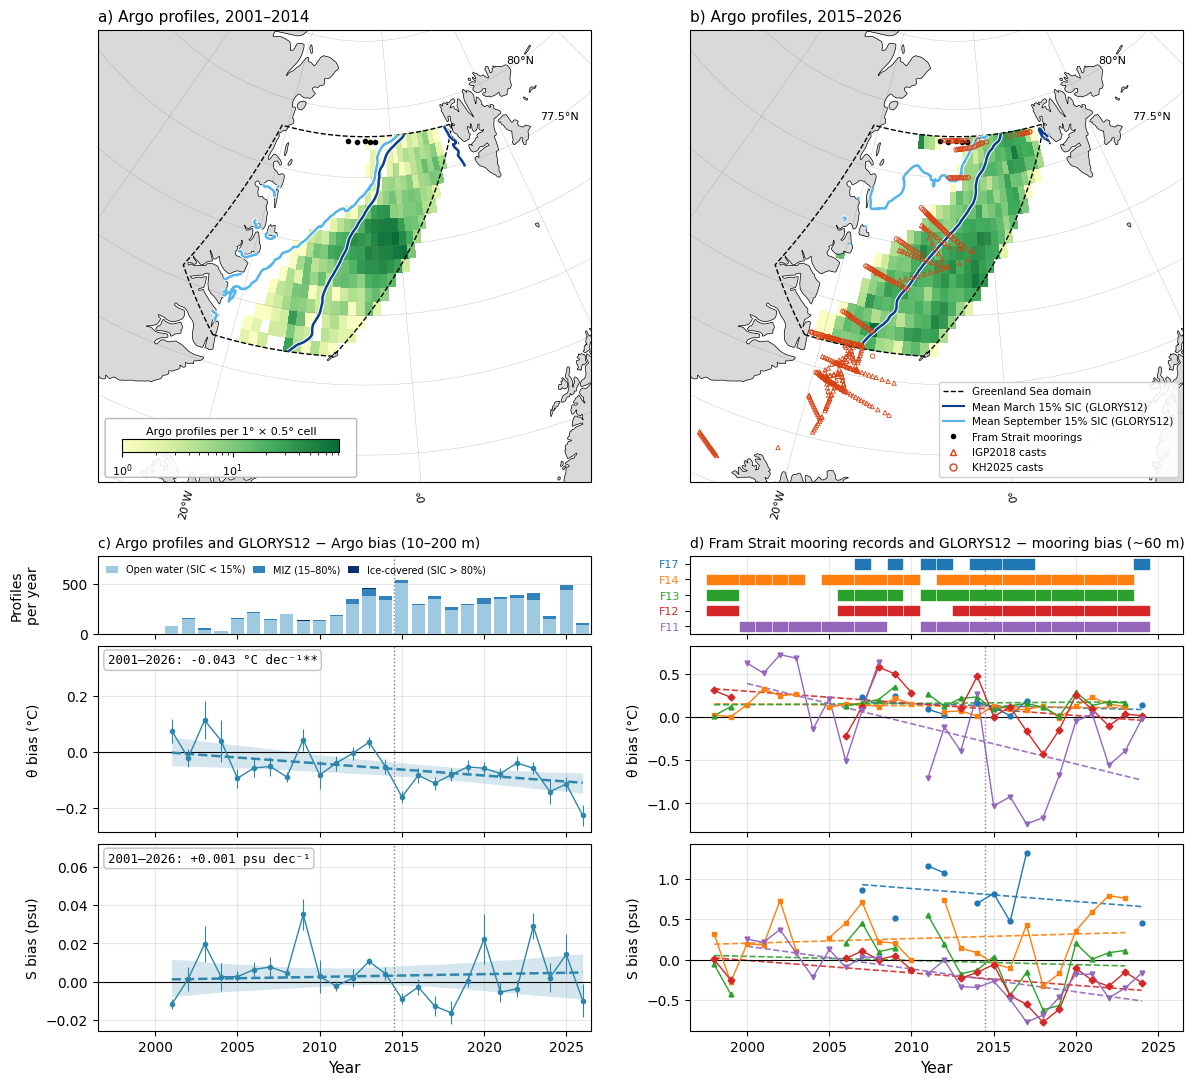

In [17]:
def draw_map(ax, sub, sic_field, title, norm, casts=None, sic_sep=None):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    lon_edges = np.arange(MAP_EXTENT[0], MAP_EXTENT[1] + GRID_DLON, GRID_DLON)
    lat_edges = np.arange(MAP_EXTENT[2], MAP_EXTENT[3] + GRID_DLAT, GRID_DLAT)
    H, _, _ = np.histogram2d(sub['lon'], sub['lat'], bins=[lon_edges, lat_edges])
    H = np.ma.masked_equal(H.T, 0)
    mesh = ax.pcolormesh(lon_edges, lat_edges, H, norm=norm, cmap=CMAP_COUNTS,
                         transform=ccrs.PlateCarree(), zorder=1)
    if DRAW_COASTLINES:
        ax.add_feature(cfeature.LAND, facecolor='0.85', zorder=2)
        ax.coastlines('50m', linewidth=0.5, zorder=3)
    poly_dense = densify_polygon(GREENLAND_SEA_COORDS)
    ax.plot(poly_dense[:, 0], poly_dense[:, 1], color='k', ls='--', lw=1.0,
            transform=ccrs.PlateCarree(), zorder=4)
    cs = ax.contour(sic_field['longitude'], sic_field['latitude'], sic_field.values,
                    levels=[ICE_EDGE_SIC], colors=COLOR_ICE_EDGE, linewidths=1.8,
                    transform=ccrs.PlateCarree(), zorder=4.5)
    # White halo so the ice edge stays visible over dense cells
    halo = [pe.Stroke(linewidth=3.2, foreground='white'), pe.Normal()]
    contours = [cs]
    if sic_sep is not None:
        contours.append(ax.contour(sic_sep['longitude'], sic_sep['latitude'], sic_sep.values,
                                   levels=[ICE_EDGE_SIC], colors=COLOR_ICE_EDGE_SEP, linewidths=1.8,
                                   transform=ccrs.PlateCarree(), zorder=4.5))
    for c_ in contours:
        try:
            c_.set(path_effects=halo)              # matplotlib >= 3.8
        except (AttributeError, ValueError):
            for coll in c_.collections:            # older matplotlib
                coll.set_path_effects(halo)
    for mid, (la, lo) in MOORING_POSITIONS.items():
        ax.plot(lo, la, 'o', color='k', ms=3, transform=ccrs.PlateCarree(), zorder=5)
    if casts is not None and not casts.empty:
        for camp, mkr in [('IGP2018', '^'), ('KH2025', 'o')]:
            c = casts[casts['campaign'] == camp]
            ax.scatter(c['lon'], c['lat'], marker=mkr, s=10, facecolors='none',
                       edgecolors='#D84315', linewidths=0.6,
                       transform=ccrs.PlateCarree(), zorder=5)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='0.5', alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    ax.set_title(title, fontsize=FONTSIZE, loc='left')
    return mesh


def plot_bias_axis(ax, a, trends, color, ylabel, unit, title=None):
    ax.plot(a.index.values, a['mean_bias'].values, '-', color=color, lw=1, zorder=3)
    ax.errorbar(a.index.values, a['mean_bias'].values, yerr=a['se'].values, fmt='o',
                color=color, ms=3, elinewidth=0.8, capsize=0, zorder=4)
    ax.axhline(0, color='k', lw=0.8)
    ax.axvline(BREAK_X_ANNUAL, color='grey', ls=':', lw=1)
    lines = []
    for p in TREND_PERIODS:
        r = trends.get(p)
        if r is None:
            continue
        ax.fill_between(r['x_line'], r['ci_lo'], r['ci_hi'], color=color, alpha=0.2, lw=0)
        ax.plot(r['x_line'], r['y_line'], '--', color=color, lw=1.8)
        lines.append(f"{r['year_start']}–{r['year_end']}: "
                     f"{r['slope_per_decade']:+.3f} {unit} dec⁻¹{sig_stars(r['p'])}")
    if lines:
        ax.text(0.02, 0.96, '\n'.join(lines), transform=ax.transAxes, va='top', ha='left',
                fontsize=STATS_FS, fontfamily='monospace',
                bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec='0.7'))
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + STATS_HEADROOM * (hi - lo))   # keep stats box clear of data
    ax.set_ylabel(ylabel, fontsize=FONTSIZE - 1)
    ax.grid(alpha=0.3)
    if title:
        ax.set_title(title, fontsize=FONTSIZE, loc='left')


def plot_trend_scatter(ax, tbl, unit, title, style_fn):
    vals = []
    for _, r in tbl.iterrows():
        col, mkr = style_fn(r['site'])
        xerr = [[max(0, r['slope_obs'] - r['ci_obs_lo'])], [max(0, r['ci_obs_hi'] - r['slope_obs'])]]
        yerr = [[max(0, r['slope_glorys'] - r['ci_glorys_lo'])],
                [max(0, r['ci_glorys_hi'] - r['slope_glorys'])]]
        ax.errorbar(r['slope_obs'], r['slope_glorys'], xerr=xerr, yerr=yerr, fmt='none',
                    ecolor=col, elinewidth=0.8, alpha=0.6, zorder=2)
        ax.scatter(r['slope_obs'], r['slope_glorys'], marker=mkr, s=45,
                   facecolors=col if r['period'] == 'P2' else 'white',
                   edgecolors=col, linewidths=1.3, zorder=3)
        vals += [r['ci_obs_lo'], r['ci_obs_hi'], r['ci_glorys_lo'], r['ci_glorys_hi']]
    v = np.array(vals + [0.0], dtype=float)
    v = v[np.isfinite(v)]
    if v.size > 1:
        lo, hi = v.min(), v.max()
        pad = 0.08 * (hi - lo) if hi > lo else 1.0
        lo, hi = lo - pad, hi + pad
        # identical tick positions on both axes so x and y read the same
        ticks = MaxNLocator(nbins=7, steps=[1, 2, 2.5, 5, 10]).tick_values(lo, hi)
        ticks = ticks[(ticks >= lo) & (ticks <= hi)]
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.plot([lo, hi], [lo, hi], color='0.4', ls='--', lw=1, zorder=1)
    ax.axhline(0, color='0.75', lw=0.6, zorder=0)
    ax.axvline(0, color='0.75', lw=0.6, zorder=0)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel(f'Observed trend ({unit} dec$^{{-1}}$)', fontsize=FONTSIZE - 2)
    ax.set_ylabel(f'GLORYS12 trend ({unit} dec$^{{-1}}$)', fontsize=FONTSIZE - 2)
    ax.tick_params(labelsize=FONTSIZE - 3)
    ax.set_title(title, fontsize=FONTSIZE - 1, loc='left')
    ax.grid(alpha=0.3)


def mooring_style(site):
    return MOORING_COLORS.get(site, 'k'), MOORING_MARKERS.get(site, 'o')


def fsaoo_style(site):
    return 'k', 'o'


p1_years = df_argo.loc[df_argo['period'] == 'P1', 'year']
p2_years = df_argo.loc[df_argo['period'] == 'P2', 'year']
lab_p1 = f"{int(p1_years.min())}–{SPLIT_YEAR - 1}" if len(p1_years) else f"<{SPLIT_YEAR}"
lab_p2 = f"{SPLIT_YEAR}–{int(p2_years.max())}" if len(p2_years) else f"≥{SPLIT_YEAR}"

# ---------------- Figure S5: observing network and Argo bias drift (a–d) ----------------
FIG1_WSPACE = 0.2     # same value in both grids keeps map, (c) and (d) edges aligned
fig = plt.figure(figsize=(14, 13))
outer = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1.0, 1.05],
                          hspace=0.16, wspace=FIG1_WSPACE)   # hspace leaves room for longitude labels
# top block: maps only (colorbar is inset in panel a)
top = outer[0, :].subgridspec(1, 2, wspace=FIG1_WSPACE)

# Row 1: maps. adjustable='datalim' lets each map fill its grid cell, so the map
# frames line up exactly with panels (c) and (d) below.
proj = ccrs.NorthPolarStereo(central_longitude=-5)
ax_a = fig.add_subplot(top[0, 0], projection=proj)
ax_b = fig.add_subplot(top[0, 1], projection=proj)

lon_edges = np.arange(MAP_EXTENT[0], MAP_EXTENT[1] + GRID_DLON, GRID_DLON)
lat_edges = np.arange(MAP_EXTENT[2], MAP_EXTENT[3] + GRID_DLAT, GRID_DLAT)
hmax = max(np.histogram2d(df_argo.loc[df_argo['period'] == p, 'lon'],
                          df_argo.loc[df_argo['period'] == p, 'lat'],
                          bins=[lon_edges, lat_edges])[0].max() for p in ['P1', 'P2'])
norm = LogNorm(vmin=1, vmax=max(hmax, 2))

m = draw_map(ax_a, df_argo[df_argo['period'] == 'P1'], ds_edge['sic_P1'],
             f"a) Argo profiles, {lab_p1}", norm, sic_sep=ds_edge['sic_sep_P1'])
draw_map(ax_b, df_argo[df_argo['period'] == 'P2'], ds_edge['sic_P2'],
         f"b) Argo profiles, {lab_p2}", norm, casts=df_casts, sic_sep=ds_edge['sic_sep_P2'])
for ax_ in (ax_a, ax_b):
    ax_.set_adjustable('datalim')

map_handles = [
    Line2D([], [], color='k', ls='--', lw=1, label='Greenland Sea domain'),
    Line2D([], [], color=COLOR_ICE_EDGE, lw=1.5, label='Mean March 15% SIC (GLORYS12)'),
    Line2D([], [], color=COLOR_ICE_EDGE_SEP, lw=1.5, label='Mean September 15% SIC (GLORYS12)'),
    Line2D([], [], color='k', marker='o', ls='none', ms=3, label='Fram Strait moorings'),
    Line2D([], [], color='#D84315', marker='^', ls='none', mfc='none', ms=5, label='IGP2018 casts'),
    Line2D([], [], color='#D84315', marker='o', ls='none', mfc='none', ms=5, label='KH2025 casts'),
]
ax_b.legend(handles=map_handles, loc='lower right', fontsize=7.5, framealpha=0.9)

# Shared colorbar, inset at the bottom left of panel (a) on a white box
CB_BOX   = (0.02, 0.015, 0.50, 0.12)     # axes fraction: x, y, width, height
CB_INSET = [0.05, 0.065, 0.44, 0.03]    # colorbar axes within panel (a)
ax_a.add_patch(FancyBboxPatch(CB_BOX[:2], *CB_BOX[2:], boxstyle='round,pad=0.005',
                              transform=ax_a.transAxes, fc='white', ec='0.7', alpha=0.9, zorder=6))
cax = ax_a.inset_axes(CB_INSET)
cax.set_zorder(7)
cb = fig.colorbar(m, cax=cax, orientation='horizontal')
cb.set_label(f'Argo profiles per {GRID_DLON:g}° × {GRID_DLAT:g}° cell', fontsize=FONTSIZE - 3, labelpad=3)
cb.ax.xaxis.set_label_position('top')
cb.ax.tick_params(labelsize=FONTSIZE - 3)

# Row 3: (c) Argo and (d) moorings — each a coverage strip above θ and S bias panels
STRIP_RATIOS = [0.42, 1, 1]
cgs = outer[1, 0].subgridspec(3, 1, height_ratios=STRIP_RATIOS, hspace=0.08)
egs = outer[1, 1].subgridspec(3, 1, height_ratios=STRIP_RATIOS, hspace=0.08)
ax_c = fig.add_subplot(cgs[0])
ax_cT = fig.add_subplot(cgs[1], sharex=ax_c)
ax_cS = fig.add_subplot(cgs[2], sharex=ax_c)
ax_d = fig.add_subplot(egs[0], sharex=ax_c)
ax_dT = fig.add_subplot(egs[1], sharex=ax_c)
ax_dS = fig.add_subplot(egs[2], sharex=ax_c)

yr_min = min(coverage.index.min(), int(moor_ann['year'].min()))
yr_max = max(coverage.index.max(), int(moor_ann['year'].max()), SPLIT_YEAR)
XLIM = (yr_min - 0.5, yr_max + 0.5)

# (c) strip: Argo profiles per year by GLORYS12 sea-ice class
bottom = np.zeros(len(coverage))
for cls in ICE_CLASSES:
    vals = coverage[cls].values
    if vals.sum() == 0:
        continue
    ax_c.bar(coverage.index.values, vals, bottom=bottom, width=0.8,
             color=ICE_CLASS_COLORS[cls], label=ICE_CLASS_LABELS[cls], zorder=3)
    bottom += vals
ax_c.axvline(BREAK_X_ANNUAL, color='grey', ls=':', lw=1)
ax_c.set_ylabel('Profiles\nper year', fontsize=FONTSIZE - 1)
ax_c.set_ylim(0, coverage['total'].max() * 1.45)          # headroom for the legend
ax_c.legend(fontsize=7, loc='upper left', ncol=3, frameon=False, handlelength=1.2, columnspacing=0.8)
ax_c.grid(axis='y', alpha=0.3, zorder=0)
ax_c.set_title(f'c) Argo profiles and GLORYS12 − Argo bias ({ARGO_DEPTH_MIN:g}–{ARGO_DEPTH_MAX:g} m)',
               fontsize=FONTSIZE - 1, loc='left')

plot_bias_axis(ax_cT, ann['T'], ann_trends['T'], COLOR_T, 'θ bias (°C)', '°C')
plot_bias_axis(ax_cS, ann['S'], ann_trends['S'], COLOR_S, 'S bias (psu)', 'psu')

# (d) strip: years with a valid annual mooring bias (>= MOOR_MIN_MONTHS months)
for k, mid_ in enumerate(MOORING_ORDER):
    yrs = moor_ann.loc[(moor_ann['mooring'] == mid_) & moor_ann['S_mean_bias'].notna(), 'year'].values
    ax_d.broken_barh([(y - 0.45, 0.9) for y in yrs], (k - 0.3, 0.6), color=MOORING_COLORS[mid_], zorder=3)
ax_d.set_yticks(range(len(MOORING_ORDER)))
ax_d.set_yticklabels(MOORING_ORDER, fontsize=FONTSIZE - 3)
for lab, mid_ in zip(ax_d.get_yticklabels(), MOORING_ORDER):
    lab.set_color(MOORING_COLORS[mid_])
ax_d.set_ylim(len(MOORING_ORDER) - 0.5, -0.5)              # F17 (west) at top
ax_d.axvline(BREAK_X_ANNUAL, color='grey', ls=':', lw=1)
ax_d.grid(axis='x', alpha=0.3, zorder=0)
ax_d.set_title('d) Fram Strait mooring records and GLORYS12 − mooring bias (~60 m)',
               fontsize=FONTSIZE - 1, loc='left')

# (d) bias panels: annual means per mooring; optional thin full-record trends, no shading
for ax_, v, ylab in [(ax_dT, 'T', 'θ bias (°C)'), (ax_dS, 'S', 'S bias (psu)')]:
    for mid_ in MOORING_ORDER:
        a_ = moor_ann[moor_ann['mooring'] == mid_].set_index('year').reindex(range(yr_min, yr_max + 1))
        col = MOORING_COLORS[mid_]
        ax_.plot(a_.index, a_[f'{v}_mean_bias'], '-', color=col, lw=1, zorder=3)   # breaks at gaps
        ax_.plot(a_.index, a_[f'{v}_mean_bias'], MOORING_MARKERS[mid_], color=col, ms=3.5, zorder=4)
        r = moor_trends[v].get(mid_)
        if MOORING_TRENDS and r is not None:
            ax_.plot(r['x_line'], r['y_line'], '--', color=col, lw=1.2, alpha=0.9, zorder=2)
    ax_.axhline(0, color='k', lw=0.8)
    ax_.axvline(BREAK_X_ANNUAL, color='grey', ls=':', lw=1)
    ax_.set_ylabel(ylab, fontsize=FONTSIZE - 1)
    ax_.grid(alpha=0.3)

for ax_ in (ax_c, ax_cT, ax_d, ax_dT):
    plt.setp(ax_.get_xticklabels(), visible=False)
for ax_ in (ax_cS, ax_dS):
    ax_.set_xlabel('Year', fontsize=FONTSIZE)
ax_c.set_xlim(XLIM)
fig.align_ylabels([ax_c, ax_cT, ax_cS])
fig.align_ylabels([ax_d, ax_dT, ax_dS])

fig.savefig(OUT_FIG, dpi=FIG_DPI, bbox_inches='tight')
logger.info(f"Figure saved: {OUT_FIG}")
plt.show()

## Section 8b — Figure S6: trend fidelity at fixed sites (2 × 2)

INFO:__main__:Figure saved: ./outputs/figures/figure_s06_trend_fidelity.png


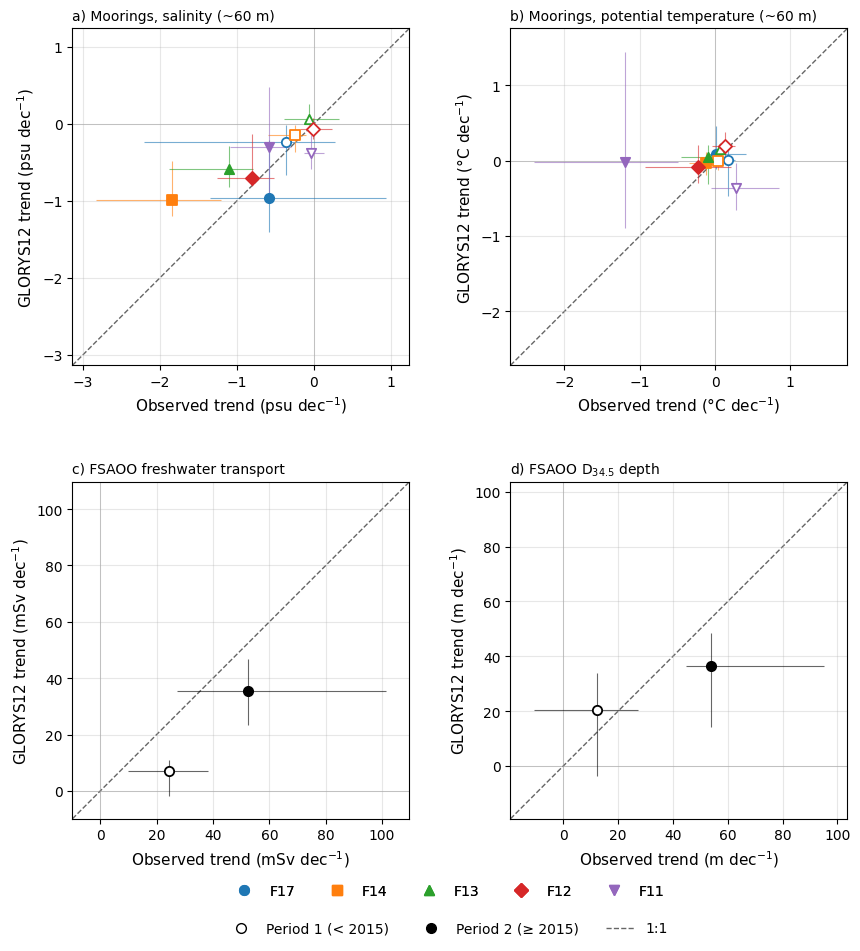

In [11]:
fig2, axs2 = plt.subplots(2, 2, figsize=(10, 10.6))
ax_ta, ax_tb, ax_tc, ax_td = axs2.ravel()
if not df_fid.empty:
    moor = df_fid[df_fid['site'].isin(MOORING_ORDER)]
    plot_trend_scatter(ax_ta, moor[moor['variable'] == 'S'], 'psu',
                       'a) Moorings, salinity (~60 m)', mooring_style)
    plot_trend_scatter(ax_tb, moor[moor['variable'] == 'T'], '°C',
                       'b) Moorings, potential temperature (~60 m)', mooring_style)
    plot_trend_scatter(ax_tc, df_fid[df_fid['variable'] == 'FWT'], 'mSv',
                       'c) FSAOO freshwater transport', fsaoo_style)
    plot_trend_scatter(ax_td, df_fid[df_fid['variable'] == 'D345'], 'm',
                       'd) FSAOO D$_{34.5}$ depth', fsaoo_style)
for ax_ in axs2.ravel():
    ax_.tick_params(labelsize=FONTSIZE - 1)
    ax_.xaxis.label.set_size(FONTSIZE)
    ax_.yaxis.label.set_size(FONTSIZE)
    ax_.title.set_size(FONTSIZE)
fig2.subplots_adjust(hspace=0.25, wspace=0.3)

moor_handles = [Line2D([], [], color=MOORING_COLORS[mm], marker=MOORING_MARKERS[mm], ls='none',
                       mfc=MOORING_COLORS[mm], ms=7, label=mm) for mm in MOORING_ORDER]
per_handles = [Line2D([], [], color='k', marker='o', ls='none', mfc='white', ms=7,
                      label=f'Period 1 (< {SPLIT_YEAR})'),
               Line2D([], [], color='k', marker='o', ls='none', mfc='k', ms=7,
                      label=f'Period 2 (≥ {SPLIT_YEAR})'),
               Line2D([], [], color='0.4', ls='--', lw=1, label='1:1')]
fig2.canvas.draw()   # resolve equal-aspect axes positions before placing the legend
y_bottom = min(a.get_position().y0 for a in axs2.ravel())
leg1 = fig2.legend(handles=moor_handles, loc='upper center', ncol=len(moor_handles), fontsize=10,
                   bbox_to_anchor=(0.5, y_bottom - 0.05), frameon=False)
fig2.add_artist(leg1)
fig2.legend(handles=per_handles, loc='upper center', ncol=len(per_handles), fontsize=10,
            bbox_to_anchor=(0.5, y_bottom - 0.085), frameon=False)

fig2.savefig(OUT_FIG_2, dpi=FIG_DPI, bbox_inches='tight')
logger.info(f"Figure saved: {OUT_FIG_2}")
plt.show()

## Section 9 — Additional diagnostic: rolling mooring bias with gaps broken

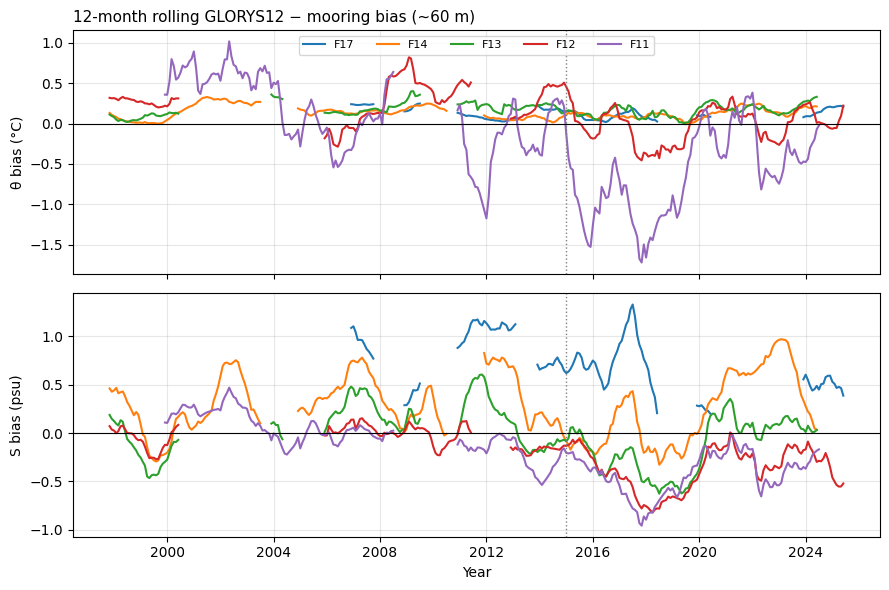

In [12]:
fig_r, axes_r = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for mid_ in MOORING_ORDER:
    sub = df_moor[df_moor['mooring'] == mid_].copy()
    if sub.empty:
        continue
    sub['month'] = sub['time'].dt.to_period('M').dt.to_timestamp()
    sub = sub.groupby('month')[['T_pot', 'S', 'glorys_T', 'glorys_S']].mean()
    sub = sub.asfreq('MS')     # missing months become NaN -> lines break at gaps
    tb = (sub['glorys_T'] - sub['T_pot']).rolling(12, center=True, min_periods=9).mean()
    sb = (sub['glorys_S'] - sub['S']).rolling(12, center=True, min_periods=9).mean()
    axes_r[0].plot(tb.index, tb.values, color=MOORING_COLORS[mid_], label=mid_)
    axes_r[1].plot(sb.index, sb.values, color=MOORING_COLORS[mid_], label=mid_)
for ax_, ylab in zip(axes_r, ['θ bias (°C)', 'S bias (psu)']):
    ax_.axhline(0, color='k', lw=0.8)
    ax_.axvline(pd.Timestamp(f'{SPLIT_YEAR}-01-01'), color='grey', ls=':', lw=1)
    ax_.set_ylabel(ylab, fontsize=FONTSIZE - 1)
    ax_.grid(alpha=0.3)
axes_r[0].legend(ncol=5, fontsize=8, loc='upper center')
axes_r[1].set_xlabel('Year')
axes_r[0].set_title('12-month rolling GLORYS12 − mooring bias (~60 m)', fontsize=FONTSIZE, loc='left')
fig_r.tight_layout()
fig_r.savefig(OUT_FIG_REF, dpi=FIG_DPI, bbox_inches='tight')
plt.show()

## Section 10 — Methodology

In [13]:
def fmt_trend_line(r, unit):
    return (f"| {r['site']} | {r['variable']} | {r['period']} | {r['start']}–{r['end']} | "
            f"{r['n_months']} | {r['slope_obs']:+.4f} [{r['ci_obs_lo']:+.4f}, {r['ci_obs_hi']:+.4f}]"
            f"{sig_stars(r['mk_p_obs'])} | "
            f"{r['slope_glorys']:+.4f} [{r['ci_glorys_lo']:+.4f}, {r['ci_glorys_hi']:+.4f}]"
            f"{sig_stars(r['mk_p_glorys'])} | "
            f"{r['diff']:+.4f} [{r['ci_diff_lo']:+.4f}, {r['ci_diff_hi']:+.4f}] | {unit} dec⁻¹ |")


UNITS = {'S': 'psu', 'T': '°C', 'FWT': 'mSv', 'D345': 'm'}


def write_methodology():
    L = []
    L += ["# Figures S5 and S6 — Sensitivity of GLORYS12 to changes in the in-situ observing network", "",
          "## Purpose",
          "Tests whether the pre/post-2015 changes diagnosed from GLORYS12 could be artefacts of",
          "changes in the observing network (reviewer comment on MIZ coverage), and whether",
          "GLORYS12 reproduces observed trends where the network did not change (reviewer",
          "comment on dataset fidelity, e.g. Fig. S4).", "",
          "## Conventions",
          f"- SPLIT_YEAR = {SPLIT_YEAR}; Period 1 = year < {SPLIT_YEAR}, Period 2 = year >= {SPLIT_YEAR}.",
          f"- On annual axes (c, d) the break line is drawn at {BREAK_X_ANNUAL} because annual values sit",
          f"  on integer years and {SPLIT_YEAR} belongs to Period 2.",
          f"- Bootstrap: n = {N_BOOTSTRAP}, seed = {SEED}.", "",
          "## Data and independence",
          "- Argo: paired Argo/GLORYS12 profile file used for Fig. S2. Argo profiles are",
          "  assimilated by GLORYS12, so panel (c) is a consistency check of the GLORYS12-Argo",
          "  mismatch through time, NOT independent validation.",
          "- Fram Strait moorings F11–F17 (NPI; one instrument at ~60 m each), monthly means with",
          "  >= 90% coverage, collocated as in Fig. S3.",
          "- FSAOO freshwater transport and D34.5 isohaline depth, as in Fig. S4.",
          "- IGP2018 and KH2025 cast positions are shown in (b) for context only.", "",
          "## Methods",
          f"- Argo band means: {ARGO_DEPTH_MIN:g}–{ARGO_DEPTH_MAX:g} m, computed over levels where BOTH Argo and",
          f"  GLORYS12 are finite (joint mask); profiles with < {ARGO_MIN_LEVELS} jointly valid levels dropped.",
          "  Temperature compared as potential temperature (Argo stored as potential T; GLORYS12",
          "  thetao). Profiles restricted to the Greenland Sea polygon.",
          f"- Sea-ice class: nearest-neighbour GLORYS12 siconc at profile location and month;",
          f"  open water < {MIZ_SIC_MIN}, MIZ {MIZ_SIC_MIN}–{MIZ_SIC_MAX}, ice-covered > {MIZ_SIC_MAX}.",
          "  GLORYS12 siconc is NaN over ice-free ocean; with SIC_NAN_OVER_OCEAN = "
          f"'{SIC_NAN_OVER_OCEAN}', NaN",
          "  siconc at ocean cells (finite surface thetao) is set to 0 for both the profile",
          "  classification and the March-mean ice edge.",
          f"- Maps: profile counts on a {GRID_DLON:g}° × {GRID_DLAT:g}° grid; ice edges = {ICE_EDGE_SIC} contours of",
          "  GLORYS12 March-mean and September-mean siconc per period.",
          f"- Panel (c): annual mean of per-profile Argo bias (region = {BIAS_REGION}); years with",
          f"  < {ANNUAL_MIN_PROFILES} profiles excluded (i.e. all years kept when 1). "
          + ('Single linear trend over the whole record (not split at SPLIT_YEAR: the panel tests whether '
             'the GLORYS12-Argo mismatch is stationary, so the physical breakpoint is not imposed). Fitted by'
             if ANNUAL_TREND_MODE == 'full' else 'Trend per period by'),
          f"  {'weighted least squares, weight = profiles per year' if ANNUAL_WEIGHTING == 'n' else 'OLS'};",
          "  error bars = +/-1 standard error of each annual mean; significance from scipy",
          "  Kendall tau (annual aggregates); CI from full trend lines per bootstrap replicate",
          "  (pointwise 2.5/97.5 percentiles).",
          "- Figure S6 (a–d): within each period, obs and GLORYS12 restricted to identical months;",
          "  each deseasonalised against its own monthly climatology from those months. OLS trend",
          "  per decade; significance from Yue-Wang modified Mann-Kendall (applied to the matched",
          "  sequence, i.e. gaps are not interpolated). 95% CIs from a moving-block bootstrap",
          f"  (block = {BLOCK_LEN} months) using the same resampled blocks for obs, GLORYS12 and their",
          f"  difference. Site-periods with < {MIN_MONTHS} matched months or < {MIN_SPAN_YEARS:g} years span",
          "  are excluded.", ""]

    L += ["## Results — panel (c) Argo annual bias trends", "",
          "| var | period | years | n | trend (per decade) | Kendall tau | p |",
          "|---|---|---|---|---|---|---|"]
    for v in ['T', 'S']:
        for p in TREND_PERIODS:
            r = ann_trends[v].get(p)
            if r is not None:
                L.append(f"| {v} | {p} | {r['year_start']}–{r['year_end']} | {r['n']} | "
                         f"{r['slope_per_decade']:+.4f} {UNITS[v]}{sig_stars(r['p'])} | "
                         f"{r['tau']:+.3f} | {r['p']:.3f} |")
    L += ["", "## Results — panel (d) mooring annual bias trends (full record, OLS; Kendall tau)",
          f"Calendar-year means of monthly GLORYS12 − mooring bias at ~60 m; years with < {MOOR_MIN_MONTHS} months excluded.",
          "", "| var | mooring | years | n | trend (per decade) | Kendall tau | p |", "|---|---|---|---|---|---|---|"]
    for _, r in df_moor_trends.iterrows():
        L.append(f"| {r['var']} | {r['mooring']} | {r['year_start']}–{r['year_end']} | {r['n_years']} | "
                 f"{r['slope_per_decade']:+.4f} {UNITS[r['var']]}{sig_stars(r['p'])} | {r['tau']:+.3f} | {r['p']:.3f} |")
    L += ["", "## Sensitivity — panel (c) trends to weighting, sparse years, the partial final year",
          f"({PARTIAL_LAST_YEAR}: data to {DATA_END_DATE} only) and restriction to open-water profiles", "",
          "| var | case | period | n years | trend (per decade) | Kendall tau | p |",
          "|---|---|---|---|---|---|---|"]
    for _, r in df_sens.iterrows():
        L.append(f"| {r['var']} | {r['case']} | {r['period']} | {r['n_years']} | "
                 f"{r['slope_per_decade']:+.4f} {UNITS[r['var']]}{sig_stars(r['p'])} | "
                 f"{r['tau']:+.3f} | {r['p']:.3f} |")
    L += ["", "## Results — annual bias / RMSE vs annual profile count", "",
          "| var | metric | n years | Pearson r | p | Kendall tau | p |", "|---|---|---|---|---|---|---|"]
    for _, r in df_density.iterrows():
        L.append(f"| {r['var']} | {r['metric']} | {r['n_years']} | {r['pearson_r']:+.3f} | "
                 f"{r['pearson_p']:.3f} | {r['kendall_tau']:+.3f} | {r['kendall_p']:.3f} |")

    L += ["", "## Results — trend fidelity (Figure S6 a–d)",
          "Trend [95% block-bootstrap CI]; asterisks = Yue-Wang MK significance.", "",
          "| site | var | period | months | n | obs trend | GLORYS12 trend | GLORYS12 − obs | units |",
          "|---|---|---|---|---|---|---|---|---|"]
    for _, r in df_fid.iterrows():
        L.append(fmt_trend_line(r, UNITS.get(r['variable'], '')))
    if not df_fid.empty:
        n_ex = int(df_fid['diff_ci_excludes_zero'].sum())
        L += ["", f"Site-periods where the GLORYS12 − obs trend difference CI excludes zero: "
                  f"{n_ex} of {len(df_fid)}."]

    L += ["", "## Results — Argo statistics by sea-ice class and period", "",
          "| period | ice class | var | n | r | bias | RMSE |", "|---|---|---|---|---|---|---|"]
    for _, r in df_ic.iterrows():
        L.append(f"| {r['period']} | {r['ice_class']} | {r['variable']} | {r['n']} | "
                 f"{r['r']:.3f} | {r['bias']:+.4f} | {r['rmse']:.4f} |")

    n_ice = int((df_argo['ice_class'] == 'ice_covered').sum())
    L += ["", f"Note: the ice-covered class holds only {n_ice} profiles in total (floats avoid",
          "ice), so its statistics are not interpreted."]
    L += ["", "## Results — platform statistics by period", "",
          "| platform | site | var | period | n | r | bias | RMSE |", "|---|---|---|---|---|---|---|---|"]
    for _, r in df_plat.iterrows():
        L.append(f"| {r['platform']} | {r['site']} | {r['variable']} | {r['period']} | {r['n']} | "
                 f"{r['r']:.3f} | {r['bias']:+.4f} | {r['rmse']:.4f} |")

    L += ["", "## Coverage", "",
          f"Argo profiles per ice class (all years): "
          f"{df_argo['ice_class'].value_counts().to_dict()}"]
    with open(MD_METHODS, 'w') as f:
        f.write('\n'.join(L) + '\n')
    logger.info(f"Methodology written: {MD_METHODS}")


write_methodology()

INFO:__main__:Methodology written: ./outputs/methods/figure_s05_methodology.md
